<a href="https://colab.research.google.com/github/halid06-git/bot_practic_halid/blob/main/07-segment/lesson.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---
# Часть 1. EDA: смотрим на данные

In [120]:
df = pd.read_csv("ner_news.csv")
sentences = [s.split(" ") for s in df["tokens"]]
tags = [t.split(" ") for t in df["tags"]]
print(df.head(3).to_string())
show_tags(sentences[0], tags[0])
show_tags(sentences[7], tags[7])

                                                                                                                                                                                                       tokens                                                                     tags
0                                                                            Дополнение : Д . Медведев присвоил звания сотрудников полиции и переназначил 14 руководителей УВД , ГУВД и МВД по субъектам РФ .  O O B-PER I-PER I-PER O O O O O O O O B-ORG O B-ORG O B-ORG O O B-LOC O
1  Президент России Дмитрий Медведев присвоил звания сотрудников полиции и переназначил 14 руководителей управлений , главных управлений и министерств внутренних дел по субъектам РФ и федеральным округам .    O B-LOC B-PER I-PER O O O O O O O O O O O O O O O O O O B-LOC O O O O
2                                                                                                                                                                  

**Схема тегов BIO:** `B-` — первое слово сущности (**B**egin), `I-` — продолжение (**I**nside), `O` — всё остальное (**O**utside). Благодаря этому «Дмитрий Медведев» — одна сущность: `B-PER I-PER`. Набор: Collection3, русские новости.

### ✏️ Задание 1. Сколько предложений `n_sent` и сколько всего слов `n_words`?

In [121]:
n_sent = len(sentences)
n_words = sum(len(s) for s in sentences)

In [122]:
#@title 🧪 Проверка задания 1 { display-mode: "form" }
if check([
    ('предложений', lambda: n_sent == len(df), 'Сколько элементов в списке sentences?'),
    ('слов', lambda: n_words == sum(len(x) for x in sentences), 'Нужно сложить длины всех предложений'),
], 1):
    print(f"{n_sent} предложений, {n_words} слов")

✅ Тест 1: предложений
✅ Тест 2: слов

🎉 Задание 1 выполнено!
13064 предложений, 267620 слов


<details><summary>💡 Подсказка</summary>

`sum` умеет складывать значения из генератора.
</details>
<details><summary>🆘 Почти готовый ответ</summary>

```python
n_sent = ___(sentences)
n_words = sum(___ for s in sentences)
```
</details>

### ✏️ Задание 2. Посчитайте теги: `tag_counts` (Counter) и долю тега O `share_o`

In [123]:
tag_counts = Counter()
for sent_tags in tags:
    tag_counts.update(sent_tags)

share_o = tag_counts["O"] / sum(tag_counts.values())

✅ Тест 1: тегов 7 видов
✅ Тест 2: доля O

🎉 Задание 2 выполнено!


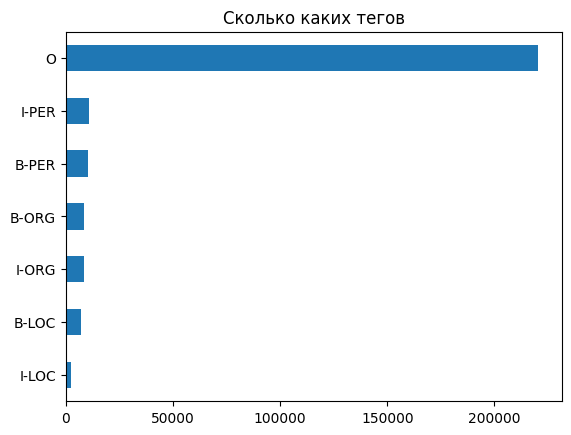

Тег O: 82.4%. Запомните это число!


In [124]:
#@title 🧪 Проверка задания 2 { display-mode: "form" }
if check([
    ('тегов 7 видов', lambda: len(tag_counts) == 7, 'Добавьте в счётчик теги каждого предложения'),
    ('доля O', lambda: 0.8 < share_o < 0.9, 'Число O разделите на число всех тегов'),
], 2):
    pd.Series(tag_counts).sort_values().plot.barh(title="Сколько каких тегов"); plt.show()
    print(f"Тег O: {share_o:.1%}. Запомните это число!")

<details><summary>💡 Подсказка</summary>

У Counter есть метод `update`, а `values()` даёт все счётчики.
</details>
<details><summary>🆘 Почти готовый ответ</summary>

```python
tag_counts.___(t)
share_o = tag_counts["O"] / sum(___)
```
</details>

### ✏️ Задание 3. Длины предложений: `lengths` и `MAX_LEN` — длина, в которую укладываются 95% предложений

In [125]:
lengths = [len(s) for s in sentences]
MAX_LEN = int(np.percentile(lengths, 95))

✅ Тест 1: список длин
✅ Тест 2: 95-й перцентиль

🎉 Задание 3 выполнено!


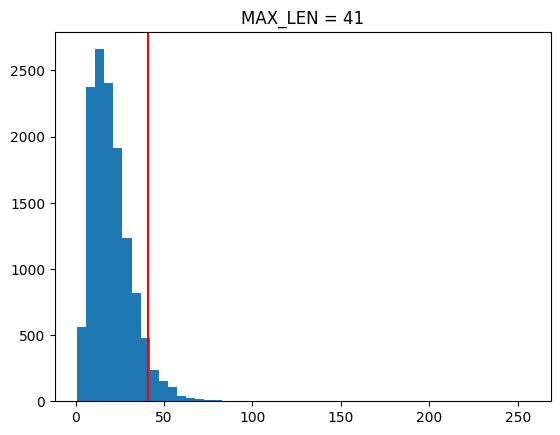

Сеть принимает батч одной длины: длинные обрежем, короткие дополним.


In [126]:
#@title 🧪 Проверка задания 3 { display-mode: "form" }
if check([
    ('список длин', lambda: len(lengths) == n_sent, 'Длина для каждого предложения'),
    ('95-й перцентиль', lambda: MAX_LEN == int(np.percentile(lengths, 95)), 'В numpy есть функция percentile'),
], 3):
    plt.hist(lengths, bins=50); plt.axvline(MAX_LEN, color="r"); plt.title(f"MAX_LEN = {MAX_LEN}"); plt.show()
    print("Сеть принимает батч одной длины: длинные обрежем, короткие дополним.")

<details><summary>💡 Подсказка</summary>

Посмотрите `np.percentile(a, q)`. Результат приведите к int.
</details>

---
# Часть 2. Разделение и предобработка

**Важно:** сначала делим, потом строим словарь. Иначе данные проверки «протекут» в обучение.

### ✏️ Задание 4. Разделите данные: 80% train, 10% val, 10% test

In [118]:
idx = np.arange(n_sent)
train_idx, rest_idx = train_test_split(idx, test_size=0.2, random_state=42)
val_idx, test_idx = train_test_split(rest_idx, test_size=0.5, random_state=42)

In [119]:
#@title 🧪 Проверка задания 4 { display-mode: "form" }
if check([
    ('train около 80%', lambda: abs(len(train_idx) / n_sent - 0.8) < 0.01, 'test_size=0.2 в первом разбиении'),
    ('val и test поровну', lambda: abs(len(val_idx) - len(test_idx)) <= 1, 'Остаток делим пополам'),
    ('не пересекаются', lambda: not set(train_idx) & set(test_idx) and not set(val_idx) & set(test_idx), 'Второй раз делите rest_idx'),
], 4):
    print(len(train_idx), len(val_idx), len(test_idx))
    print("train учит, val выбирает гиперпараметры, test — честная оценка один раз в конце.")

✅ Тест 1: train около 80%
✅ Тест 2: val и test поровну
✅ Тест 3: не пересекаются

🎉 Задание 4 выполнено!
10451 1306 1307
train учит, val выбирает гиперпараметры, test — честная оценка один раз в конце.


<details><summary>💡 Подсказка</summary>

`train_test_split` вызывается дважды.
</details>
<details><summary>🆘 Почти готовый ответ</summary>

```python
train_idx, rest_idx = train_test_split(idx, test_size=___, random_state=42)
val_idx, test_idx = train_test_split(___, test_size=___, random_state=42)
```
</details>

### ✏️ Задание 5. Постройте словарь `word2idx` только по train: слова в нижнем регистре, встретившиеся минимум 2 раза

In [85]:
PAD, UNK = 0, 1

counts = Counter(w.lower() for i in train_idx for w in sentences[i])
word2idx = {"<PAD>": PAD, "<UNK>": UNK}
for w, c in counts.items():
    if c >= 2:
        word2idx[w] = len(word2idx)

In [86]:
#@title 🧪 Проверка задания 5 { display-mode: "form" }
if check([
    ('служебные токены', lambda: word2idx["<PAD>"] == 0 and word2idx["<UNK>"] == 1, 'Не меняйте первые два элемента'),
    ('только частые слова', lambda: len(word2idx) == 2 + sum(c >= 2 for c in counts.values()), 'Добавляйте слово, только если c >= 2'),
    ('номера без дыр', lambda: sorted(word2idx.values()) == list(range(len(word2idx))), 'Следующий номер равен текущей длине словаря'),
], 5):
    print("Размер словаря:", len(word2idx), "из", len(counts))

✅ Тест 1: служебные токены
✅ Тест 2: только частые слова
✅ Тест 3: номера без дыр

🎉 Задание 5 выполнено!
Размер словаря: 13275 из 28527


<details><summary>💡 Подсказка</summary>

Какое значение всегда свободно в растущем словаре? Его текущая длина.
</details>

In [87]:
tag2idx = {t: i for i, t in enumerate(sorted(tag_counts))}
idx2tag = {i: t for t, i in tag2idx.items()}
print(tag2idx)

{'B-LOC': 0, 'B-ORG': 1, 'B-PER': 2, 'I-LOC': 3, 'I-ORG': 4, 'I-PER': 5, 'O': 6}


### ✏️ Задание 6. Функция `encode(words)`: слова → номера. Незнакомое слово → UNK, регистр нижний

In [88]:
def encode(words):
    return [word2idx.get(w.lower(), UNK) for w in words]

In [89]:
#@title 🧪 Проверка задания 6 { display-mode: "form" }
if check([
    ('знакомое слово', lambda: encode(["и"]) == [word2idx["и"]], 'Ищите слово в word2idx'),
    ('регистр', lambda: encode(["И"]) == [word2idx["и"]], 'Сначала приведите к нижнему регистру'),
    ('незнакомое', lambda: encode(["ъъъъъ"]) == [UNK], 'У словаря есть метод get со значением по умолчанию'),
], 6):
    print(sentences[0][:6], "→", encode(sentences[0][:6]))

✅ Тест 1: знакомое слово
✅ Тест 2: регистр
✅ Тест 3: незнакомое

🎉 Задание 6 выполнено!
['Дополнение', ':', 'Д', '.', 'Медведев', 'присвоил'] → [1, 151, 562, 5, 563, 9485]


<details><summary>💡 Подсказка</summary>

`словарь.get(ключ, запасное_значение)`.
</details>

### ✏️ Задание 7. Функция `pad(seq, value)`: обрезать до MAX_LEN или дополнить значением value

In [90]:
def pad(seq, value):
    seq = seq[:MAX_LEN]
    return seq + [value] * (MAX_LEN - len(seq))

In [91]:
#@title 🧪 Проверка задания 7 { display-mode: "form" }
if check([
    ('короткая', lambda: pad([5], 0) == [5] + [0] * (MAX_LEN - 1), 'Сколько значений не хватает до MAX_LEN?'),
    ('длинная', lambda: len(pad([1] * 500, 0)) == MAX_LEN, 'Длина должна быть ровно MAX_LEN'),
], 7):
    pass

✅ Тест 1: короткая
✅ Тест 2: длинная

🎉 Задание 7 выполнено!


<details><summary>💡 Подсказка</summary>

Список можно умножить на число.
</details>

In [92]:
def to_tensors(ids):
    X = torch.tensor([pad(encode(sentences[i]), PAD) for i in ids])
    # -100: на дополненных позициях сеть не штрафуем
    Y = torch.tensor([pad([tag2idx[t] for t in tags[i]], -100) for i in ids])
    return X, Y

X_train, Y_train = to_tensors(train_idx)
X_val, Y_val = to_tensors(val_idx)
X_test, Y_test = to_tensors(test_idx)
print(X_train.shape, Y_train.shape)

torch.Size([10451, 41]) torch.Size([10451, 41])


---
# Часть 3. Модель

Для картинки свёртка смотрит на соседние пиксели, для текста — на **соседние слова**. «завод **КамАЗ** в» подсказывает организацию, поэтому берём `Conv1d`. Рекуррентные сети будут в следующей теме.

```
номера слов  (батч, длина)
Embedding →  (батч, длина, emb_dim)
Conv1d x2 →  (батч, filters, длина)    окно из kernel слов
Linear    →  (батч, длина, 7 тегов)    ответ для КАЖДОГО слова
```

### ✏️ Задание 8. Соберите `WordTagger`: заполните слои по схеме

In [93]:
class WordTagger(nn.Module):
    def __init__(self, vocab, n_tags, emb_dim, filters, kernel, dropout):
        super().__init__()
        self.emb = nn.Embedding(vocab, emb_dim, padding_idx=PAD)
        self.conv1 = nn.Conv1d(emb_dim, filters, kernel, padding=kernel // 2)
        self.conv2 = nn.Conv1d(filters, filters, kernel, padding=kernel // 2)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(filters, n_tags)

    def forward(self, x):
        e = self.drop(self.emb(x)).transpose(1, 2)   # (B, L, E) → (B, E, L)
        h = torch.relu(self.conv2(torch.relu(self.conv1(e))))
        return self.head(self.drop(h.transpose(1, 2)))  # (B, L, n_tags)

In [94]:
#@title 🧪 Проверка задания 8 { display-mode: "form" }
if check([
    ('форма выхода', lambda: WordTagger(100, 7, 8, 8, 3, 0.1)(torch.zeros(2, 20).long()).shape == (2, 20, 7), 'Выход: батч × длина × число тегов'),
    ('паддинг', lambda: WordTagger(100, 7, 8, 8, 3, 0.1).emb.padding_idx == 0, 'Передайте padding_idx=PAD'),
], 8):
    print(WordTagger(len(word2idx), 7, 64, 64, 3, 0.2))

✅ Тест 1: форма выхода
✅ Тест 2: паддинг

🎉 Задание 8 выполнено!
WordTagger(
  (emb): Embedding(13275, 64, padding_idx=0)
  (conv1): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,))
  (conv2): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,))
  (drop): Dropout(p=0.2, inplace=False)
  (head): Linear(in_features=64, out_features=7, bias=True)
)


<details><summary>💡 Подсказка</summary>

Посмотрите на схему: что входит в слой и что выходит.
</details>

---
# Часть 4. Метрика: почему accuracy здесь врёт

Модель, которая на **все** слова отвечает O, не находит ничего, но accuracy у неё высокая.

### ✏️ Задание 9. Посчитайте accuracy такой «ленивой» модели на val: `lazy_acc`

In [95]:
mask = Y_val != -100
lazy_acc = (Y_val[mask] == tag2idx["O"]).float().mean().item()

In [96]:
#@title 🧪 Проверка задания 9 { display-mode: "form" }
if check([
    ('значение', lambda: 0.75 < lazy_acc < 0.95, 'Какая доля настоящих тегов равна номеру O?'),
], 9):
    print(f"Ничего не найдя, модель получает accuracy {lazy_acc:.1%}! Поэтому смотрим на F1.")

✅ Тест 1: значение

🎉 Задание 9 выполнено!
Ничего не найдя, модель получает accuracy 81.9%! Поэтому смотрим на F1.


<details><summary>💡 Подсказка</summary>

Сравнение тензора с числом даёт True/False. Приведите к float и возьмите среднее.
</details>

**Precision** — сколько из найденного правильно. **Recall** — сколько из существующего нашли. **F1** — их среднее гармоническое, высокое только если хороши оба.

### ✏️ Задание 10. Модель нашла 8 сущностей, 6 верны. Всего в тексте их 12. Посчитайте `precision`, `recall`, `f1`

In [97]:
precision = 6 / 8    # 0.75
recall    = 6 / 12   # 0.5
f1        = 2 * precision * recall / (precision + recall)  # 0.6

In [98]:
#@title 🧪 Проверка задания 10 { display-mode: "form" }
if check([
    ('precision', lambda: precision == 0.75, 'Верные / найденные'),
    ('recall', lambda: recall == 0.5, 'Верные / существующие'),
    ('f1', lambda: abs(f1 - 0.6) < 1e-9, '2·P·R / (P + R)'),
], 10):
    pass

✅ Тест 1: precision
✅ Тест 2: recall
✅ Тест 3: f1

🎉 Задание 10 выполнено!


In [99]:
#@title ⚙️ Запустите: обучение и оценка (читать не обязательно) { display-mode: "form" }
ALL_TAG_IDS = [i for t, i in tag2idx.items() if t != "O"]

def predict_ids(model, X, batch=256):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), batch):
            out.append(model(X[i:i+batch].to(device)).argmax(-1).cpu())
    return torch.cat(out)

def evaluate(model, X, Y):
    """Возвращает (accuracy, F1). F1 считается по всем тегам, кроме O."""
    p, mask = predict_ids(model, X), Y != -100
    t, p = Y[mask].numpy(), p[mask].numpy()
    return (t == p).mean(), f1_score(t, p, labels=ALL_TAG_IDS, average="macro", zero_division=0)

def train_model(params, verbose=True):
    torch.manual_seed(42)
    model = WordTagger(len(word2idx), len(tag2idx), params["emb_dim"], params["filters"],
                       params["kernel"], params["dropout"]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=params["lr"])
    loss_fn = nn.CrossEntropyLoss(ignore_index=-100)
    loader = DataLoader(TensorDataset(X_train, Y_train), batch_size=params["batch"], shuffle=True)
    hist, best, best_state = [], -1, None
    for ep in range(1, params["epochs"] + 1):
        model.train(); total = 0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            loss = loss_fn(model(xb).reshape(-1, len(tag2idx)), yb.reshape(-1))
            opt.zero_grad(); loss.backward(); opt.step(); total += loss.item() * len(xb)
        acc, f1 = evaluate(model, X_val, Y_val)
        hist.append((total / len(X_train), acc, f1))
        if f1 > best:
            best, best_state = f1, {k: v.cpu().clone() for k, v in model.state_dict().items()}
        if verbose:
            print(f"эпоха {ep}: loss {hist[-1][0]:.3f} | val accuracy {acc:.3f} | val F1 {f1:.3f}")
    model.load_state_dict(best_state)
    return model, hist, best

print("✅ Готово")

✅ Готово


---
# Часть 5. Гиперпараметры

**Параметры** (веса) сеть учит сама. **Гиперпараметры** выбираем мы, до обучения:

| Что | Мало | Много |
|---|---|---|
| `lr` шаг обучения | учится долго | скачет, не сходится |
| `emb_dim` длина вектора слова | мало смысла | переобучение, медленно |
| `filters` число фильтров | не хватает сил | переобучение |
| `kernel` окно свёртки | не видит соседей | размывает |
| `dropout` | переобучение | недообучение |
| `batch`, `epochs` | шумно / не доучилась | медленно / переобучилась |

Как подбирать: **ручной перебор → сетка (grid search) → случайный поиск → Optuna**. Сравнивать только по **val**.

### ✏️ Задание 11. Задайте первые гиперпараметры и обучите модель (3 эпохи, lr 0.001)

In [100]:
params = {"emb_dim": 64, "filters": 64, "kernel": 3, "dropout": 0.2,
          "batch": 64, "lr": 0.001, "epochs": 3}
model, hist, best_f1 = train_model(params)

эпоха 1: loss 0.760 | val accuracy 0.826 | val F1 0.059
эпоха 2: loss 0.547 | val accuracy 0.863 | val F1 0.334
эпоха 3: loss 0.443 | val accuracy 0.889 | val F1 0.530


In [101]:
#@title 🧪 Проверка задания 11 { display-mode: "form" }
if check([
    ('lr', lambda: params["lr"] == 0.001, 'Запишите 0.001'),
    ('обучение прошло', lambda: best_f1 > 0.3, 'F1 должен быть заметно выше нуля; проверьте модель'),
], 11):
    print(f"Лучший val F1: {best_f1:.3f}, а у ленивой модели F1 = 0")

✅ Тест 1: lr
✅ Тест 2: обучение прошло

🎉 Задание 11 выполнено!
Лучший val F1: 0.530, а у ленивой модели F1 = 0


<details><summary>💡 Подсказка</summary>

Вписываем только два числа.
</details>

### ✏️ Задание 12. Сделайте перебор по сетке: `lr` и `kernel`, результаты в `results`

In [102]:
grid = {"lr": [0.0003, 0.003], "kernel": [3, 5]}
results = []
for lr, kernel in product(grid["lr"], grid["kernel"]):
    p = {**params, "lr": lr, "kernel": kernel, "epochs": 2}
    _, _, f1 = train_model(p, verbose=False)
    results.append({"lr": lr, "kernel": kernel, "val_f1": f1})
    print(results[-1])

table = pd.DataFrame(results).sort_values("val_f1", ascending=False)
best_row = table.iloc[0]

{'lr': 0.0003, 'kernel': 3, 'val_f1': 0.0018535681186283596}
{'lr': 0.0003, 'kernel': 5, 'val_f1': 0.019219438572655012}
{'lr': 0.003, 'kernel': 3, 'val_f1': 0.630105926386974}
{'lr': 0.003, 'kernel': 5, 'val_f1': 0.6425807152902359}


In [103]:
#@title 🧪 Проверка задания 12 { display-mode: "form" }
if check([
    ('4 запуска', lambda: len(results) == 4, 'Сетка 2 × 2'),
    ('обучение идёт', lambda: max(r["val_f1"] for r in results) > 0.2, 'Вызовите train_model(p, verbose=False)'),
    ('лучшая строка', lambda: best_row["val_f1"] == max(r["val_f1"] for r in results), 'Таблица уже отсортирована, возьмите iloc[0]'),
], 12):
    display(table)

✅ Тест 1: 4 запуска
✅ Тест 2: обучение идёт
✅ Тест 3: лучшая строка

🎉 Задание 12 выполнено!


,lr,kernel,val_f1
3,0.0030,5,0.642581
2,0.0030,3,0.630106
1,0.0003,5,0.019219
0,0.0003,3,0.001854


<details><summary>💡 Подсказка</summary>

Перебор занимает пару минут. Подумайте: сколько запусков было бы при 5 гиперпараметрах по 3 значения?
</details>

### ✏️ Задание 13. Обучите финальную модель с лучшими `lr` и `kernel` (5 эпох)

In [105]:
final_params = {
    **params,
    "lr": best_row["lr"],
    "kernel": int(best_row["kernel"]),   # ← ключевое исправление
    "epochs": 5
}

final, hist, best_f1 = train_model(final_params)

эпоха 1: loss 0.635 | val accuracy 0.865 | val F1 0.339
эпоха 2: loss 0.386 | val accuracy 0.910 | val F1 0.643
эпоха 3: loss 0.273 | val accuracy 0.929 | val F1 0.726
эпоха 4: loss 0.207 | val accuracy 0.939 | val F1 0.769
эпоха 5: loss 0.166 | val accuracy 0.944 | val F1 0.799


✅ Тест 1: лучшие значения
✅ Тест 2: качество

🎉 Задание 13 выполнено!


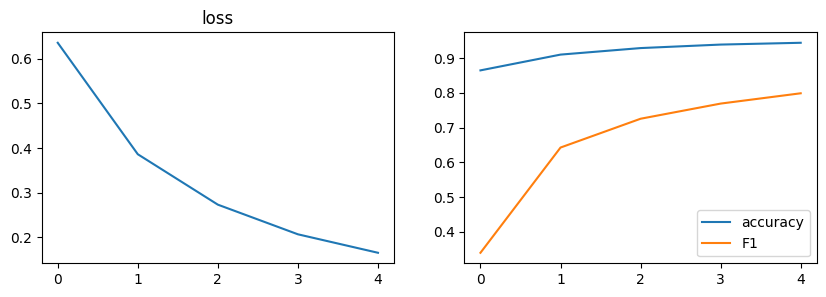

In [106]:
#@title 🧪 Проверка задания 13 { display-mode: "form" }
if check([
    ('лучшие значения', lambda: final_params["lr"] == best_row["lr"] and final_params["kernel"] == best_row["kernel"], 'Возьмите значения из best_row'),
    ('качество', lambda: best_f1 > 0.5, 'Если F1 низкий, проверьте, что lr взят из best_row'),
], 13):
    h = np.array(hist)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3)); ax[0].plot(h[:, 0]); ax[0].set_title("loss"); ax[1].plot(h[:, 1], label="accuracy"); ax[1].plot(h[:, 2], label="F1"); ax[1].legend(); plt.show()

<details><summary>💡 Подсказка</summary>

`kernel` должен быть целым: `int(...)`.
</details>

---
# Часть 6. Честная проверка на test

### ✏️ Задание 14. Посчитайте `test_acc` и `test_f1` функцией `evaluate`

In [108]:
test_acc, test_f1 = evaluate(final, X_test, Y_test)

In [109]:
#@title 🧪 Проверка задания 14 { display-mode: "form" }
if check([
    ('F1', lambda: test_f1 > 0.5, 'evaluate(модель, X, Y) с test'),
    ('accuracy выше ленивой', lambda: test_acc > lazy_acc, 'Передайте final, X_test, Y_test'),
], 14):
    print(f"accuracy {test_acc:.3f}, F1 {test_f1:.3f}")
    p, m = predict_ids(final, X_test), Y_test != -100
    print(classification_report(Y_test[m].numpy(), p[m].numpy(), labels=ALL_TAG_IDS, target_names=[idx2tag[i] for i in ALL_TAG_IDS], zero_division=0))

✅ Тест 1: F1
✅ Тест 2: accuracy выше ленивой

🎉 Задание 14 выполнено!
accuracy 0.947, F1 0.806
              precision    recall  f1-score   support

       B-LOC       0.91      0.77      0.83       726
       B-ORG       0.80      0.69      0.74       790
       B-PER       0.90      0.83      0.86       998
       I-LOC       0.91      0.73      0.81       236
       I-ORG       0.75      0.63      0.68       737
       I-PER       0.89      0.92      0.90      1022

   micro avg       0.86      0.78      0.82      4509
   macro avg       0.86      0.76      0.81      4509
weighted avg       0.86      0.78      0.81      4509



<details><summary>💡 Подсказка</summary>

Функция возвращает два числа.
</details>

### ✏️ Задание 15. Разметьте своё предложение: `my_text` и функция `tag_text`

In [110]:
my_text = "Дмитрий Медведев посетил завод КамАЗ в Татарстане"

def tag_text(text):
    words = text.split()
    x = torch.tensor([pad(encode(words), PAD)]).to(device)
    final.eval()
    with torch.no_grad():
        ids = final(x).argmax(-1)[0].cpu().tolist()
    return [idx2tag[i] for i in ids[:len(words)]]

In [111]:
#@title 🧪 Проверка задания 15 { display-mode: "form" }
if check([
    ('свой текст', lambda: isinstance(my_text, str) and len(my_text.split()) >= 4, 'Минимум 4 слова'),
    ('тег на слово', lambda: len(tag_text(my_text)) == len(my_text.split()), 'Сколько слов, столько тегов'),
], 15):
    show_tags(my_text.split(), tag_text(my_text))

✅ Тест 1: свой текст
✅ Тест 2: тег на слово

🎉 Задание 15 выполнено!


<details><summary>💡 Подсказка</summary>

Вызовите модель на x и возьмите самый вероятный класс для каждого слова.
</details>

---
# Часть 7. Из звука в текст

Новость не всегда написана: бывает запись эфира или звонка. Сначала переводим звук в текст готовым сервисом, а затем размечаем текст нашей моделью:

```
speech.wav → распознавание речи → текст → tag_text → теги
```

Библиотека `SpeechRecognition` отправляет запись в сервис Google, поэтому нужен интернет. Сервис бесплатный и без гарантий: если получили ошибку `RequestError`, подождите минуту и запустите ячейку ещё раз.

In [112]:
!pip install -q SpeechRecognition
import speech_recognition as sr
from IPython.display import Audio

if not os.path.exists("speech.wav"):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/Scr1ptG/ml_for_3p1/main/07-segment/data/speech.wav", "speech.wav")
Audio("speech.wav")

### ✏️ Задание 16. Переведите аудио-файл в текст: результат в `speech_text`

In [113]:
r = sr.Recognizer()
with sr.AudioFile("speech.wav") as source:
    content = r.record(source)

speech_text = r.recognize_google(content, language="ru-RU")

In [114]:
#@title 🧪 Проверка задания 16 { display-mode: "form" }
if check([
    ('получен текст', lambda: isinstance(speech_text, str) and len(speech_text.split()) >= 4, 'Вызовите r.recognize_google(content, language=...)'),
    ('текст верный', lambda: "завод" in speech_text.lower(), 'Проверьте язык: language="ru-RU"'),
], 16):
    print(speech_text)

✅ Тест 1: получен текст
✅ Тест 2: текст верный

🎉 Задание 16 выполнено!
Дмитрий Медведев посетил завод КАМАЗ в Татарстане


<details><summary>💡 Подсказка</summary>

`r.record(source)` читает файл, а `language` задаёт язык речи.
</details>
<details><summary>🆘 Почти готовый ответ</summary>

```python
content = r.___(source)
speech_text = r.recognize_google(___, language="ru-RU")
```
</details>

### ✏️ Задание 17. Разметьте распознанный текст своей моделью: `speech_tags`

In [115]:
speech_tags = tag_text(speech_text)

In [116]:
#@title 🧪 Проверка задания 17 { display-mode: "form" }
if check([
    ('тег на слово', lambda: len(speech_tags) == len(speech_text.split()), 'Передайте speech_text в tag_text'),
], 17):
    show_tags(speech_text.split(), speech_tags)

✅ Тест 1: тег на слово

🎉 Задание 17 выполнено!


<details><summary>💡 Подсказка</summary>

Функция уже написана, её нужно только вызвать.
</details>

---
## 🏁 Итог
EDA → разделение → словарь (только train) → паддинг → Conv1d → F1 вместо accuracy → перебор по val → один замер на test. Готовый сервис распознавания речи подключается к модели как ещё один шаг.

**Как улучшить:** предобученные эмбеддинги, LSTM (следующая тема), BERT, оценка целых сущностей через `seqeval`, готовые инструменты: `spaCy`, `Natasha`, `DeepPavlov`.